---
title: "Electric Potential and Energy — Level 2"
short_title: "02 Potential & Energy"
numbering:
  heading_2: true
  equation: true
---

# Electric Potential and Energy

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 23–24 | V from point charges, capacitor energy |
| **2** | **Griffiths, ch. 2–3** | **Poisson and Laplace equations, energy stored in the field** |
| 3 | Jackson, ch. 1–2 | Energy of charge distributions with boundaries, capacitance matrices |

The new skill at this level: replacing the vector field by a scalar potential that obeys a differential equation, and locating energy in the field itself

Math for this topic: E-M1 (vector calculus), mechanics M2 (multiple integrals) and M3 (gradient).
:::

Workbook example ladder: capacitor energy → field energy density → energy of a system of conductors. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## The Potential

Because $\nabla\times\mathbf{E} = \mathbf{0}$, the line integral of $\mathbf{E}$ between two points does not depend on the path, and a scalar **potential** exists:

$$
V(\mathbf{r}) = -\int_{\mathcal{O}}^{\mathbf{r}}\mathbf{E}\cdot d\mathbf{l}, \qquad \mathbf{E} = -\nabla V .
$$ (eq-potential-def)

The reference point $\mathcal{O}$ is usually at infinity. Only potential **differences** are physical; changing $\mathcal{O}$ adds a constant to $V$.

One scalar function carries the information of three field components. That is not a trick: the curl-free condition makes the three components dependent on each other.

For a charge distribution, superposition of point-charge potentials gives

$$
V(\mathbf{r}) = \frac{1}{4\pi\epsilon_0}\int\frac{\rho(\mathbf{r}')}{\mathscr{r}}\,d\tau' ,
$$ (eq-potential-integral)

a **scalar** integral, usually much easier than the vector integral for $\mathbf{E}$.

### Poisson's and Laplace's equations

Substituting $\mathbf{E} = -\nabla V$ into Gauss's law:

$$
\nabla^2V = -\frac{\rho}{\epsilon_0} \quad\text{(Poisson)}, \qquad \nabla^2V = 0 \ \text{where}\ \rho = 0 \quad\text{(Laplace)} .
$$ (eq-poisson)

{eq}`eq-potential-integral` is the solution of Poisson's equation in all space, by $\nabla^2(1/\mathscr{r}) = -4\pi\delta^3$ (E-M1). When conductors or other boundaries are present, the integral is not enough, and Poisson's or Laplace's equation must be solved with boundary conditions (the next topic).

### Boundary conditions on $V$

The potential is continuous across any surface charge, and its normal derivative jumps:

$$
V_{\text{above}} = V_{\text{below}}, \qquad \frac{\partial V_{\text{above}}}{\partial n} - \frac{\partial V_{\text{below}}}{\partial n} = -\frac{\sigma}{\epsilon_0} .
$$

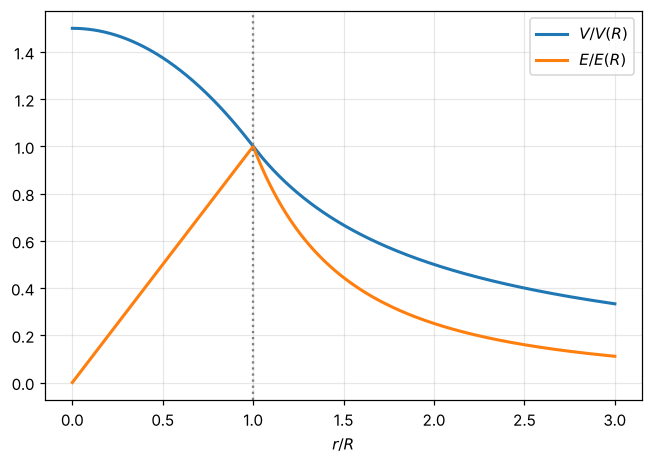

In [2]:
#| label: fig-ball-potential
#| caption: Field and potential of a uniformly charged ball of radius R (scaled so that both are 1 at the surface). V is smooth through the surface, and E = −dV/dr is continuous too, since there is no surface charge; the potential at the center is 3/2 of its surface value.
r = np.linspace(0, 3, 600)
V = np.where(r < 1, 0.5 * (3 - r**2), 1 / np.maximum(r, 1e-9))
E = np.where(r < 1, r, 1 / np.maximum(r, 1e-9)**2)
fig, ax = plt.subplots()
ax.plot(r, V, lw=2, label=r"$V / V(R)$"); ax.plot(r, E, lw=2, label=r"$E / E(R)$")
ax.axvline(1, color="gray", ls=":"); ax.set_xlabel("$r/R$"); ax.legend(); plt.show()

In [3]:
# Potential of a uniform ball from Poisson's equation
r = sp.symbols("r", positive=True)
rho, e0, R, Q, A, B = sp.symbols("rho epsilon_0 R Q A B")
Vin = A + B / r - rho * r**2 / (6 * e0)                      # general radial solution inside
print("satisfies Poisson:", sp.simplify(sp.diff(r**2 * Vin.diff(r), r) / r**2 + rho / e0) == 0)
Vin = Vin.subs(B, 0)                                          # finite at the center
rho_val = 3 * Q / (4 * sp.pi * R**3)
A_val = sp.solve(sp.Eq(Vin.subs({r: R, rho: rho_val}), Q / (4 * sp.pi * e0 * R)), A)[0]   # match the outside 1/r potential
print("V inside =", sp.simplify(Vin.subs({A: A_val, rho: rho_val})))

satisfies Poisson: True
V inside = Q*(3*R**2 - r**2)/(8*pi*R**3*epsilon_0)


### Exercises

1. Find $V$ on the axis of a uniformly charged ring (radius $a$, charge $Q$) from {eq}`eq-potential-integral`, then recover $E_z$ by differentiating.
2. A finite line segment from $z = -L$ to $z = L$ carries uniform $\lambda$. Find $V$ at distance $s$ from its midpoint, in the plane $z = 0$.
3. Show that $V = \dfrac{\rho}{6\epsilon_0}(3R^2 - r^2)$ inside a uniform ball satisfies Poisson's equation.

:::{dropdown} Hints
1. Every element is at the same distance.
2. $\int_{-L}^{L}dz/\sqrt{s^2 + z^2} = 2\sinh^{-1}(L/s)$.
3. Use the spherical Laplacian of a function of $r$ only.
:::

:::{dropdown} Answers
1. $V = \dfrac{Q}{4\pi\epsilon_0\sqrt{a^2 + z^2}}$, and $-\partial V/\partial z$ reproduces the ring field from the electrostatics notes.
2. $V = \dfrac{\lambda}{2\pi\epsilon_0}\sinh^{-1}(L/s) = \dfrac{\lambda}{2\pi\epsilon_0}\ln\dfrac{L + \sqrt{L^2 + s^2}}{s}$.
3. $\frac{1}{r^2}\frac{d}{dr}\left(r^2\cdot\frac{-\rho r}{3\epsilon_0}\right) = -\frac{\rho}{\epsilon_0}$.
:::

## Energy

Assembling point charges one at a time, bringing each in from infinity against the field of those already present, costs

$$
W = \frac12\sum_iq_iV(\mathbf{r}_i) ,
$$

where $V(\mathbf{r}_i)$ is the potential at charge $i$ due to all the **others** (the $\tfrac12$ corrects for counting each pair twice). For a continuous distribution this becomes $W = \tfrac12\int\rho V\,d\tau$. Replace $\rho$ by $\epsilon_0\nabla\cdot\mathbf{E}$, integrate by parts, and let the surface go to infinity:

$$
W = \frac{\epsilon_0}{2}\int_{\text{all space}}E^2\,d\tau .
$$ (eq-field-energy)

The energy can be thought of as stored in the **field**, with density $u = \tfrac{\epsilon_0}{2}E^2$. For static charges both pictures give the same total; once fields propagate as waves, the field picture is the only one that works.

:::{warning} Self-energy
{eq}`eq-field-energy` includes the energy needed to assemble each charge itself, which the discrete sum excludes. For a point charge that self-energy is infinite. For a uniform ball of charge $Q$ and radius $R$ it is $\frac{3}{5}\frac{Q^2}{4\pi\epsilon_0R}$. Setting that equal to $mc^2$ for an electron gives a length of order $10^{-15}$ m, the "classical electron radius", a sign that classical electrodynamics breaks down at those scales.
:::

In [4]:
# Energy of a uniformly charged ball, from the field integral
r, R, Q, e0 = sp.symbols("r R Q epsilon_0", positive=True)
E_in = Q * r / (4 * sp.pi * e0 * R**3); E_out = Q / (4 * sp.pi * e0 * r**2)
W = e0 / 2 * (sp.integrate(E_in**2 * 4 * sp.pi * r**2, (r, 0, R)) + sp.integrate(E_out**2 * 4 * sp.pi * r**2, (r, R, sp.oo)))
print("W =", sp.simplify(W), " = (3/5) Q^2 / (4 pi eps0 R)?", sp.simplify(W - sp.Rational(3, 5) * Q**2 / (4 * sp.pi * e0 * R)) == 0)

W = 3*Q**2/(20*pi*R*epsilon_0)  = (3/5) Q^2 / (4 pi eps0 R)? True


## Conductors

In a conductor, charges move freely until they stop. In equilibrium, therefore:

1. $\mathbf{E} = \mathbf{0}$ inside the material.
2. $\rho = 0$ inside (by Gauss's law); any net charge sits on the surface.
3. The whole conductor is an **equipotential**.
4. Just outside, $\mathbf{E}$ is perpendicular to the surface with magnitude $\sigma/\epsilon_0$ (from {eq}`eq-e-boundary`).

The surface charge feels an outward **pressure** $P = \sigma^2/(2\epsilon_0) = \tfrac{\epsilon_0}{2}E^2$, the field energy density.

Charge piles up where the surface is sharply curved. Two conducting spheres of radii $R_1$, $R_2$ joined by a wire share one potential, $Q_1/R_1 = Q_2/R_2$, so their surface densities satisfy $\sigma_1/\sigma_2 = R_2/R_1$: the smaller sphere has the larger surface field. That is why lightning rods are pointed and why high-voltage equipment is rounded.

### Capacitors

Two conductors carrying charges $+Q$ and $-Q$ have a potential difference proportional to $Q$. The ratio is the **capacitance**, $C = Q/\Delta V$, set purely by geometry. The energy stored is

$$
W = \frac{Q^2}{2C} = \tfrac12C\,\Delta V^2 ,
$$

which equals $\tfrac{\epsilon_0}{2}\int E^2\,d\tau$ over the space between the conductors.

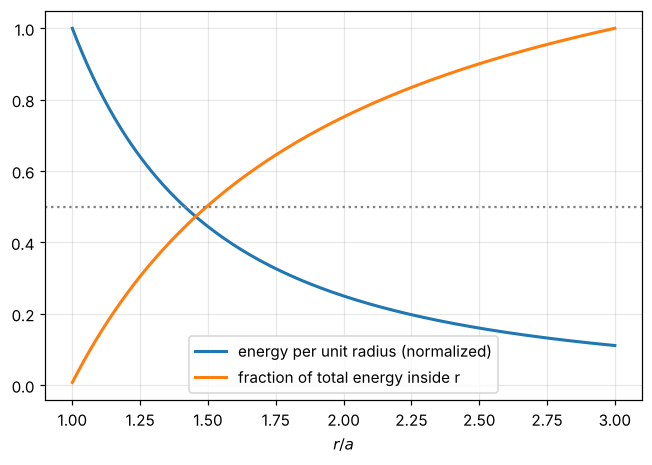

half the energy lies within r = 1.496 a   (exact: 2ab/(a+b) = 1.5a)


In [5]:
#| label: fig-capacitor-energy
#| caption: Field energy density between concentric spherical conductors (inner radius a, outer b = 3a), at fixed charge. Most of the energy sits close to the inner conductor, where the field is strongest; the curve integrates to Q²/2C.
a_, b_ = 1.0, 3.0
r = np.linspace(a_, b_, 400)
u = 1 / r**4                                    # u = (eps0/2) E^2 with E ∝ 1/r^2, unnormalized
shell = u * 4 * np.pi * r**2                    # energy per unit radius
frac = np.cumsum(shell) / np.sum(shell)
fig, ax = plt.subplots()
ax.plot(r, shell / shell.max(), lw=2, label="energy per unit radius (normalized)")
ax.plot(r, frac, lw=2, label="fraction of total energy inside r")
ax.axhline(0.5, color="gray", ls=":")
ax.set_xlabel("$r/a$"); ax.legend(); plt.show()
print("half the energy lies within r =", round(float(r[np.searchsorted(frac, 0.5)]), 3), "a   (exact: 2ab/(a+b) = 1.5a)")

### Exercises

1. Find the capacitance of two concentric spherical shells with radii $a < b$. What happens as $b\to\infty$?
2. Verify that $\tfrac{\epsilon_0}{2}\int E^2\,d\tau$ between the shells equals $Q^2/2C$.
3. Two conducting spheres, radii $1$ cm and $5$ cm, far apart, are connected by a wire and share a total charge of $12$ nC. Find each charge and the ratio of their surface fields.

:::{dropdown} Hints
1. $E = Q/(4\pi\epsilon_0r^2)$ between them; integrate to get $\Delta V$.
2. Integrate in shells, $d\tau = 4\pi r^2dr$.
3. Equal potentials: $Q_1/R_1 = Q_2/R_2$.
:::

:::{dropdown} Answers
1. $C = 4\pi\epsilon_0\dfrac{ab}{b - a}$; as $b\to\infty$, $C\to4\pi\epsilon_0a$, the capacitance of an isolated sphere.
2. $\dfrac{\epsilon_0}{2}\displaystyle\int_a^b\left(\frac{Q}{4\pi\epsilon_0r^2}\right)^24\pi r^2dr = \frac{Q^2}{8\pi\epsilon_0}\left(\frac1a - \frac1b\right) = \frac{Q^2}{2C}$.
3. $Q_1 = 2$ nC, $Q_2 = 10$ nC. $E\propto Q/R^2$, so $E_1/E_2 = (2/1)/(10/25) = 5$: the small sphere's field is five times larger.
:::

## Summary

- $\mathbf{E} = -\nabla V$, with $V$ from the scalar integral {eq}`eq-potential-integral` or from Poisson's equation {eq}`eq-poisson`.
- $V$ is continuous across surface charge; its normal derivative jumps by $-\sigma/\epsilon_0$.
- Electrostatic energy is $\tfrac12\int\rho V\,d\tau = \tfrac{\epsilon_0}{2}\int E^2\,d\tau$; the field picture includes self-energy.
- Conductors are equipotentials with $\mathbf{E} = \mathbf{0}$ inside and $\sigma/\epsilon_0$ normal just outside; charge concentrates where curvature is high.
- Capacitance is geometry: $C = Q/\Delta V$, energy $Q^2/2C$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.